In [1]:
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

Pandas: 3.1.1
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1


In [3]:
df = pd.read_csv("maize_yield_rwanda_rw.csv")

df.head()

,record_id,year,season,province,district,altitude_m,rainfall_mm,avg_temp_c,soil_ph,soil_type,seed_variety,farming_practice,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,irrigation,pest_incidence_index,yield_t_ha
0,RW-MZ-00001,2015,A,Eastern,Bugesera,1349,NaN,22.9,NaN,Clay,RHM104,Improved,117.8,57.4,1.41,61803,0.63,No,NaN,2.71
1,RW-MZ-00002,2015,A,Eastern,Bugesera,1427,489.8,22.1,6.02,Volcanic,RHM104,Improved,38.1,62.7,3.69,52919,0.17,No,0.339,4.09
2,RW-MZ-00003,2015,A,Northern,Burera,2033,722.6,16.3,5.73,Clay loam,Local,Improved,121.1,50.7,5.18,54406,0.22,No,0.049,2.58
3,RW-MZ-00004,2015,A,Northern,Burera,2026,794.4,16.4,5.20,Clay loam,ZM621,Improved,93.7,60.4,1.68,48119,0.48,No,0.171,2.45
4,RW-MZ-00005,2015,A,Northern,Gakenke,1974,644.2,18.3,5.92,Loam,Local,Improved,84.1,70.4,0.36,56787,1.16,No,0.001,2.09


In [6]:

missing_values = df.isnull().sum()

print("Missing Values per Column:\n")
print(missing_values[missing_values > 0])

Missing Values per Column:

rainfall_mm             11
soil_ph                 14
pest_incidence_index    14
dtype: int64


In [9]:

duplicates_count = df.duplicated().sum()

print(f"\nNumber of duplicate rows: {duplicates_count}")


Number of duplicate rows: 0


In [11]:
print("\n--- Summary Statistics ---")

display(df.describe())


--- Summary Statistics ---


,year,altitude_m,rainfall_mm,avg_temp_c,soil_ph,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,pest_incidence_index,yield_t_ha
count,1426.000000,1426.000000,1415.000000,1426.000000,1412.000000,1426.000000,1426.000000,1426.000000,1426.000000,1426.000000,1412.000000,1426.000000
mean,2019.506311,1704.321879,516.165371,19.404137,5.835156,66.991304,38.767602,2.083415,46322.309958,0.802104,0.283499,2.577454
std,2.855643,221.267632,155.676106,1.645486,0.443019,47.311529,31.571860,1.361537,9695.817375,0.511796,0.167093,0.700232
min,2015.000000,1243.000000,150.000000,15.400000,4.500000,0.000000,0.000000,0.000000,19337.000000,0.100000,0.001000,1.010000
25%,2017.000000,1507.000000,419.350000,18.025000,5.530000,26.300000,11.500000,1.060000,38471.500000,0.460000,0.153000,2.060000
50%,2020.000000,1702.500000,530.600000,19.400000,5.840000,62.450000,33.100000,2.005000,46901.000000,0.670000,0.261000,2.575000
75%,2022.000000,1879.750000,627.450000,20.700000,6.130000,104.975000,61.875000,3.027500,53806.250000,0.980000,0.390250,3.040000
max,2024.000000,2341.000000,933.300000,23.000000,7.200000,208.100000,135.200000,6.860000,72248.000000,4.220000,0.929000,5.150000


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

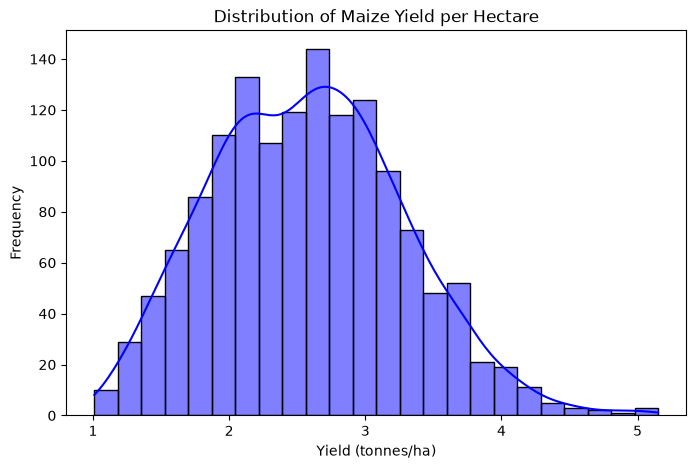

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(df['yield_t_ha'].dropna(), kde=True, color='blue')

plt.title('Distribution of Maize Yield per Hectare')
plt.xlabel('Yield (tonnes/ha)')
plt.ylabel('Frequency')

plt.show()

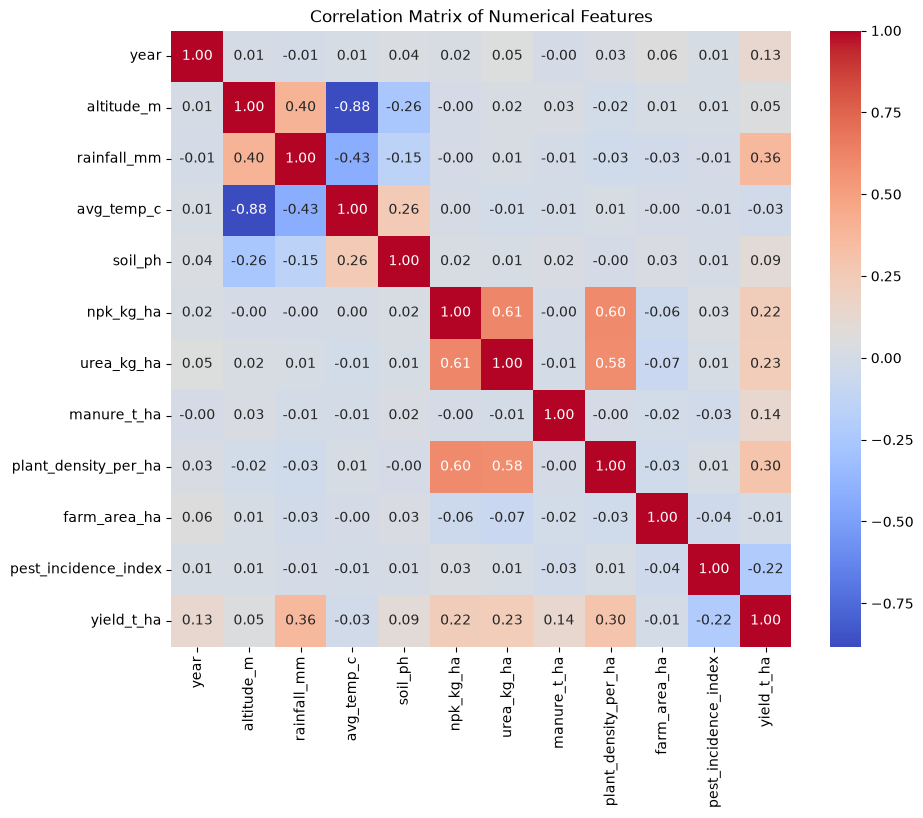

In [18]:

plt.figure(figsize=(10, 8))

numeric_cols = df.select_dtypes(include=[np.number]).columns

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix of Numerical Features')
plt.show()